# 04 — Cleaning: value rules and operation flags (stage 5)

**Purpose.** Remove impossible values with explicit, documented rules, and flag the hours in
which the plant did not run normally (stops, grid curtailment, derated inverters), without
erasing them.

**Inputs.** The stage-4 minute table (true time, sources harmonised) and
`configs/cleaning_policy.yaml`. **Outputs.** `data/processed/05_clean/` (minute and hourly
tables), `outputs/05_cleaning/`: `cleaning_manifest.json`, `cleaning_log.csv` and the applied
policy.

**Rules of the stage.**
- Every changed value has a named rule; nothing is changed silently.
- Thresholds are fixed on evidence (stage 3b, `02b_data_quality.ipynb`), not tuned on a model.
- Operation flags are kept as flags: they are excluded from the training loss and from past-day
  features, included in the main evaluation and excluded in a secondary one (D-22).

**In the original** the spikes (up to 40,825 kW), the 32,766 sentinel and the −270 °C fault code
stayed in the data, curtailment was not handled, and quality flags were used as model features
(F-14, F-17). **Where it is documented:** OP-18 to OP-28; module `solarpv.data.clean`.

## 1. The policy

In [1]:
import json

import pandas as pd
import yaml
from IPython.display import Image, display

from solarpv.config.paths import AUDIT_DIR, CONFIGS_DIR, OUTPUTS_DIR

policy = yaml.safe_load((CONFIGS_DIR / "cleaning_policy.yaml").read_text(encoding="utf-8"))
print("sections:", ", ".join(policy))
pd.DataFrame(policy["range"]).T.rename(columns={0: "low", 1: "high"})

sections: version, sun, range, range_margin_minutes, negative_to_zero, frozen_min_minutes, frozen_ignore_zero, frozen_margin_minutes, dc_dead, scale_fault, night, downtime, curtailment, derate, hourly


,low,high
ambient_temp,-20.0,60.0
site_ambient_temp,-20.0,60.0
mod_temp1,-20.0,90.0
mod_temp2,-20.0,90.0
irradiance,-20.0,1600.0
pyranometer,-20.0,1600.0
wind_speed,0.0,60.0
s01_inv1_AC_kW,-20.0,1897.0
s01_inv2_AC_kW,-20.0,1897.0
s01_inv1_DC_kW,-20.0,1897.0


**What it shows.** The sections of the policy file and the physical ranges of rule R1.

**The value rules.**
- **R1 range:** outside the physical range.
- **R2 offset:** small negative irradiance at night, set to zero.
- **R3 frozen:** a value repeated for at least 30 minutes into daytime.
- **R4 night zero:** readings of at most 5 kW below the horizon.
- **R5 night stale:** power reported with the sun more than 6° below the horizon is a stale value.
- **R6 dead DC:** DC zero while AC is produced.
- **R7 scale fault:** the second sensor's scale fault.

**The flags.** F1 `downtime`, F2 `curtail` and F3 `derate`, together `op_limited_flag`.

## 2. What each rule changed

In [2]:
log = pd.read_csv(OUTPUTS_DIR / "05_cleaning" / "cleaning_log.csv")
log.sort_values(["column", "rule"])

,rule,column,minutes,daytime_minutes,hours_touched,kwh_changed
0,R1_range,ambient_temp,2698,335,70,NaN
1,R3_frozen,ambient_temp,7823,3309,144,NaN
2,R2_offset,irradiance,57738,2,2283,NaN
3,R3_frozen,irradiance,8993,3655,169,NaN
4,R1_range,mod_temp1,2139,278,53,NaN
5,R3_frozen,mod_temp1,7991,3462,154,NaN
6,R1_range,mod_temp2,2093,278,53,NaN
7,R3_frozen,mod_temp2,7948,3426,152,NaN
8,R3_frozen,pyranometer,8460,3340,157,NaN
9,R7_scale_fault,pyranometer,409160,178857,6826,NaN


**What it shows.** Per rule and column: minutes changed, how many in daylight, the hours
touched, and for power the energy removed.

**What it means.**
- On the inverters' AC power, the range rule removed 12
  minutes, the spikes. The frozen-value rule removed 11,336
  minutes of communication freezes.
- The largest count, 409,160 minutes, is the scale fault of the second irradiance
  sensor, which is only a quality check (D-09). The main sensor is not affected.

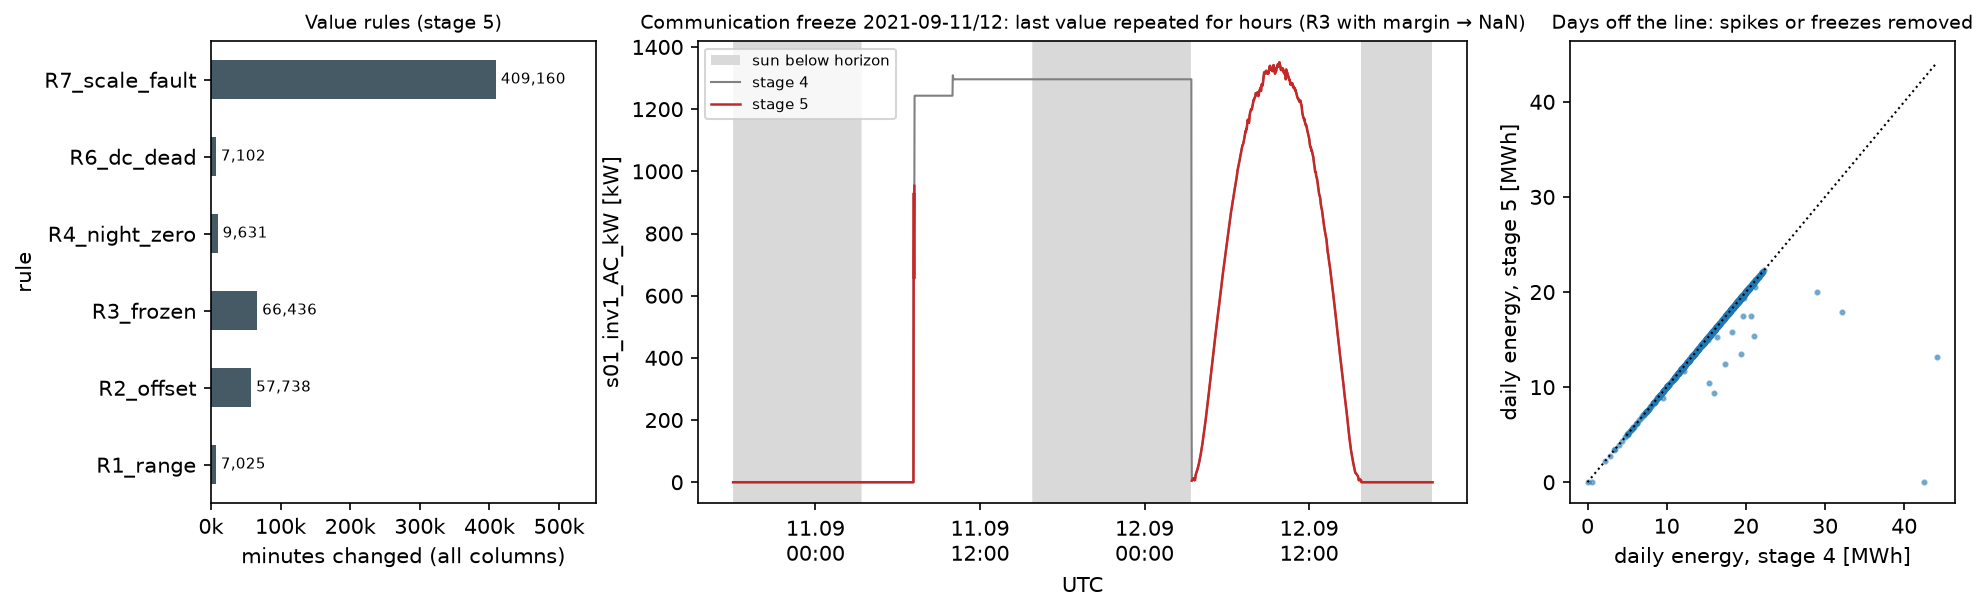

In [3]:
display(Image("../outputs/03_eda/figures/fig05_cleaning.png", width=900))

**What it shows.** The communication freeze of 11–12 September 2021, before and after
cleaning: the logger repeated its last values for hours, including about 1,300 kW in the middle
of the night, and the frozen run is removed. Daily energy is unchanged on every day except the few
with spikes or freezes (right panel).

**Effect on the target.** The highest hourly site total falls from a spike-driven value to
2,948.4 kW (99.99th percentile
2,894.6 kW), below the 3,449 kW AC capacity.

## 3. Operation flags

In [4]:
manifest = json.loads((OUTPUTS_DIR / "05_cleaning" / "cleaning_manifest.json")
                      .read_text(encoding="utf-8"))
pd.DataFrame(manifest["hours_by_split"]).T

,daytime_hours,op_limited_hours,hours_with_downtime,hours_with_curtailment,hours_with_derate,target_nan_hours,polled_hours,mixed_hours
train,9698,379,110,59,245,42,0,0
val,2902,146,18,90,43,1,0,0
test,2580,186,37,73,93,5,1001,70


**What it shows.** Per split, the daytime hours and the hours touched by each flag.

**What it means.**
- **Op-limited hours:** train 379, validation
  146 and test 186.
- **Curtailment** is frequent in validation and test. A model that learned it as weather would be
  wrong, and that is why the flags never enter as features.
- **The test split** has 1001 hours from the second source of 2025
  and 70 mixed hours. They are also reported separately
  (D-21).

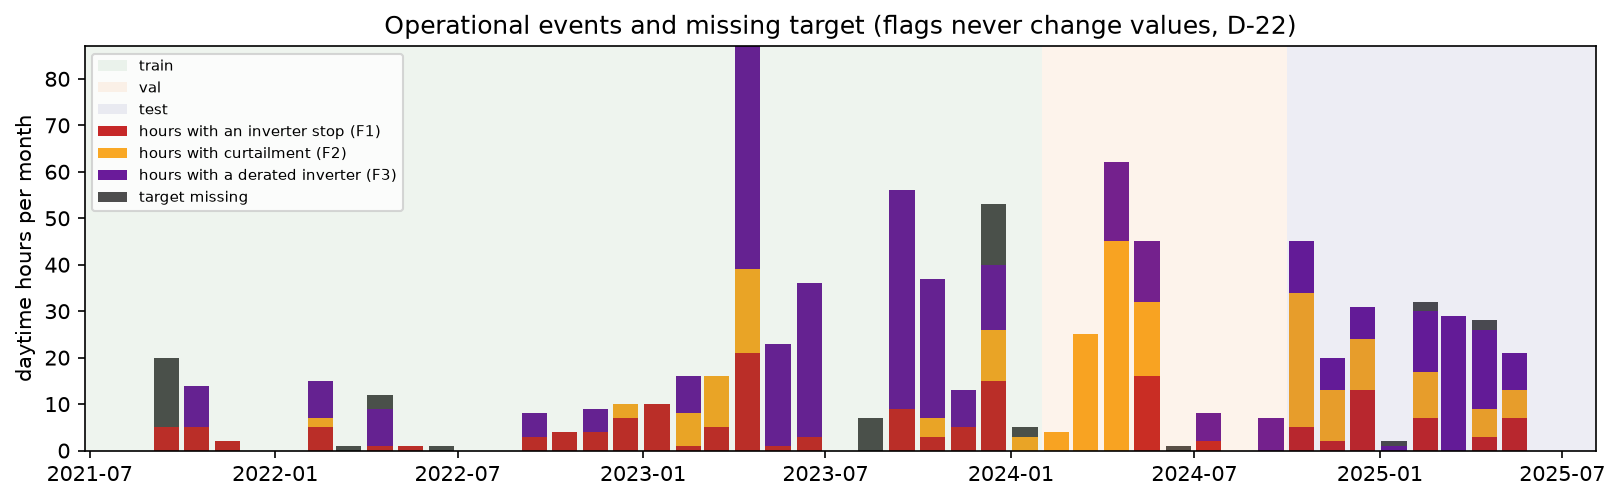

In [5]:
display(Image("../outputs/03_eda/figures/fig09_operations.png", width=900))

**What it shows.** Flagged daytime hours per month and type: stops, curtailment and
derates.

**What it means.** The flags are not rare, and they cluster: derates in 2023, curtailment in
spring and autumn 2024. Without them a model would treat equipment and grid limits as weather.

## 4. Does the cleaning code catch what it should?

In [6]:
print((AUDIT_DIR / "cleaning_2026-10-15" / "mutation_check_output.txt")
      .read_text(encoding="utf-8"))

caught      value changed without a rule
caught      daytime production zeroed, labelled as night rule
caught      T-16 on the same fault
caught      spike left in place (reconciliation)
caught      spike left in place (ranges)
caught      frozen run partly kept
caught      flag changed a value
caught      curtailment minute not flagged
caught      manifest count off by one
caught      derated minute not flagged
caught      setpoint drift flagged as curtailment
caught      pyranometer scale fault kept



**What it shows.** A mutation check: 12 deliberate faults were planted in the
code or the data (a value changed without a rule, production zeroed as night, a spike left in place,
a curtailment minute not flagged, and so on). The test suite caught 12 of 12.

**What it means.** The tests of the cleaning stage fail when the cleaning is wrong, not only when
it crashes.

**Next stage.** Stage 6 (`04b_features_target.ipynb`) builds the targets and the features on the
cleaned hours.

**Reproduce.** `python -m solarpv.data.clean`, then `python scripts/make_cleaning_notebook.py`.